# Notebook 2.0: Stratified Sampling & Temporal Coverage Audit (2018–2022)

**Research Phase 2 — Data Ingestion & Sampling**

This notebook:
1. Discovers raw Parquet files in `data/raw/` across all 7 target subreddits (including `QualityAssurance`).
2. Extracts ISO-week stratified samples (up to 30,000 rows per file within `2018-01-01` to `2022-12-31`) into `data/samples/2.0/`, skipping re-sampling if all 14 expected sample JSONs already exist.
3. Audits UTC timestamps to confirm full 2018–2022 coverage with zero 1970 epoch-collapse bugs.
4. Generates a weekly coverage plot (`data/final/figures/fig0_weekly_coverage_audit.png`) and exports audit tables to `data/final/`.

In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
nb_dir = Path.cwd()
project_root = nb_dir.parent if nb_dir.name == 'notebooks' else nb_dir
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import yaml
import pandas as pd
import matplotlib.pyplot as plt

from src.modeling import set_seed
from src.ingest.sampling import get_parquet_from_path, stratified_sample_parquet_to_json
from src.modeling.load import load_samples

# Load configuration
config_path = project_root / 'config' / 'config.yaml'
with open(config_path, 'r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)

seed = int(cfg['modeling']['seed'])
set_seed(seed)

raw_data_dir = (project_root / cfg['paths']['raw_data_dir']).resolve()
samples_output_dir = project_root / cfg['paths']['data_samples_dir'] / '2.0'
final_dir = project_root / cfg['paths']['final_dir']
tables_dir = final_dir / 'tables'
fig_dir = final_dir / 'figures'
for d in (samples_output_dir, tables_dir, fig_dir):
    d.mkdir(parents=True, exist_ok=True)

subreddits = cfg['analysis']['subreddits']
dataset_types = cfg['analysis']['dataset_types']
start_date = cfg['analysis']['start_date']
end_date = cfg['analysis']['end_date']
desired_samples = int(cfg['analysis']['sample_size'])

print(f'Subreddits ({len(subreddits)}): {subreddits}')
print(f'Analysis window: {start_date} to {end_date}')
print(f'Samples output dir: {samples_output_dir}')

Subreddits (7): ['cscareerquestions', 'cscareerquestionsEU', 'datascience', 'dataengineering', 'cybersecurity', 'SoftwareEngineering', 'QualityAssurance']
Analysis window: 2018-01-01 to 2022-12-31
Samples output dir: /home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/data/samples/2.0


## Step 1: Discover Raw Parquet Files
Locate the expected `{subreddit}_{dataset_type}.parquet` files under `data/raw/`.

In [2]:
all_parquet_files = get_parquet_from_path(raw_data_dir)
target_files = []
for sub in subreddits:
    for dtype in dataset_types:
        direct_fp = raw_data_dir / f'{sub}_{dtype}.parquet'
        if direct_fp.exists():
            target_files.append(str(direct_fp))
        else:
            matches = [p for p in all_parquet_files if Path(p).name == f'{sub}_{dtype}.parquet']
            if matches:
                target_files.append(matches[0])
            else:
                print(f'Warning: Missing expected parquet file for {sub}_{dtype}')

print(f'Discovered {len(target_files)} target parquet files (of {len(all_parquet_files)} total):')
for pf in sorted(target_files):
    print('  -', Path(pf).name)

Discovered 14 target parquet files (of 14 total):
  - QualityAssurance_comments.parquet
  - QualityAssurance_submissions.parquet
  - SoftwareEngineering_comments.parquet
  - SoftwareEngineering_submissions.parquet
  - cscareerquestionsEU_comments.parquet
  - cscareerquestionsEU_submissions.parquet
  - cscareerquestions_comments.parquet
  - cscareerquestions_submissions.parquet
  - cybersecurity_comments.parquet
  - cybersecurity_submissions.parquet
  - dataengineering_comments.parquet
  - dataengineering_submissions.parquet
  - datascience_comments.parquet
  - datascience_submissions.parquet


## Step 2: Stratified Sampling by ISO Week (`2018-01-01` to `2022-12-31`)
Skip re-sampling if all 14 expected JSON files already exist in `data/samples/2.0/`.

In [3]:
expected_names = {f'{sub}_{dtype}.json' for sub in subreddits for dtype in dataset_types}
existing_names = {p.name for p in samples_output_dir.glob('*.json')}

if expected_names.issubset(existing_names):
    print(f'All {len(expected_names)} expected sample JSONs already exist in {samples_output_dir}; skipping re-sampling.')
else:
    print(f'Extracting stratified samples ({desired_samples:,} max/file, {start_date}..{end_date}) to: {samples_output_dir}')
    stratified_sample_parquet_to_json(
        file_paths=target_files,
        output_dir=samples_output_dir,
        desired_samples=desired_samples,
        seed=seed,
        start_date=start_date,
        end_date=end_date,
    )

All 14 expected sample JSONs already exist in /home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/data/samples/2.0; skipping re-sampling.


## Step 3: Load Samples & Audit UTC Timestamps
Verify that all sampled timestamps fall strictly within `2018-01-01` to `2022-12-31`.

In [4]:
df_samples = load_samples(
    samples_dir=samples_output_dir,
    subreddits=subreddits,
    dataset_types=dataset_types,
)

start_ts = pd.Timestamp(start_date, tz='UTC')
end_ts = pd.Timestamp(end_date, tz='UTC') + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)
df_samples = (
    df_samples[(df_samples['created_utc_dt'] >= start_ts) & (df_samples['created_utc_dt'] <= end_ts)]
    .copy()
    .reset_index(drop=True)
)

print(f'Total clean records loaded ({start_date}..{end_date}): {len(df_samples):,}')
audit_table = (
    df_samples.groupby(['subreddit', 'dataset_type'])['created_utc_dt']
    .agg(min_date='min', max_date='max', total_rows='count')
    .reset_index()
)
print(audit_table.to_string(index=False))

min_date = df_samples['created_utc_dt'].min()
max_date = df_samples['created_utc_dt'].max()
assert min_date.year >= 2018 and max_date.year <= 2022, (
    f'Error: detected out-of-window timestamp bounds {min_date}..{max_date} (expected 2018-2022)!'
)
print(f'Timestamp validation passed: {min_date.date()} to {max_date.date()} (zero 1970 timestamps).')

/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])


/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])
/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])


/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])


/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])


/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])
/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])


/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])


/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])


/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])
/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])


/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])
/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])


/home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/src/modeling/load.py:57: UserWarning: parse_created_utc: string column detected — assuming ISO 8601 format.
  df["created_utc_dt"] = parse_created_utc(df["created_utc"])


Total clean records loaded (2018-01-01..2022-12-31): 330,902
          subreddit dataset_type                  min_date                  max_date  total_rows
   QualityAssurance     comments 2018-01-01 17:24:57+00:00 2022-12-31 22:22:02+00:00       29048
   QualityAssurance  submissions 2018-01-01 16:55:43+00:00 2022-12-31 06:41:08+00:00        6119
SoftwareEngineering     comments 2018-01-02 06:48:02+00:00 2022-12-31 19:38:45+00:00       27731
SoftwareEngineering  submissions 2018-01-01 04:17:03+00:00 2022-12-31 23:17:44+00:00        8377
  cscareerquestions     comments 2018-01-01 00:24:18+00:00 2022-12-31 23:07:53+00:00       28147
  cscareerquestions  submissions 2018-01-01 00:22:11+00:00 2022-12-31 19:26:16+00:00       29998
cscareerquestionsEU     comments 2018-01-02 10:07:09+00:00 2022-12-31 19:49:55+00:00       29064
cscareerquestionsEU  submissions 2018-01-02 10:17:29+00:00 2022-12-31 16:45:50+00:00       13500
      cybersecurity     comments 2018-01-03 01:35:00+00:00 2022-12

## Step 4: Temporal Coverage Plot
Plot weekly sampled volume across all 7 subreddits with key 2018–2022 macroeconomic milestones.

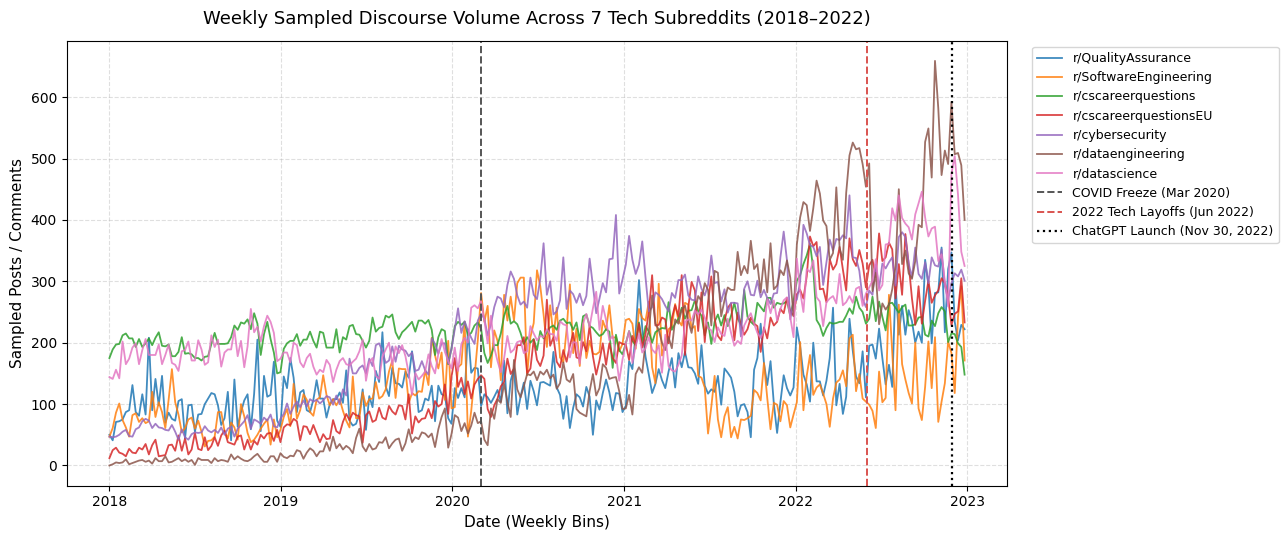

Coverage figure saved to: /home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/data/final/figures/fig0_weekly_coverage_audit.png


In [5]:
df_samples['week'] = (
    pd.to_datetime(df_samples['created_utc_dt'], utc=True)
    .dt.tz_convert(None)
    .dt.to_period('W')
    .dt.start_time
)
weekly_volume = df_samples.groupby(['week', 'subreddit']).size().unstack(fill_value=0)

plt.figure(figsize=(13, 5.5))
for sub in sorted(weekly_volume.columns):
    plt.plot(weekly_volume.index, weekly_volume[sub], label=f'r/{sub}', alpha=0.85, linewidth=1.3)

plt.axvline(pd.Timestamp('2020-03-01'), color='#555555', linestyle='--', linewidth=1.4, label='COVID Freeze (Mar 2020)')
plt.axvline(pd.Timestamp('2022-06-01'), color='#d9534f', linestyle='--', linewidth=1.4, label='2022 Tech Layoffs (Jun 2022)')
plt.axvline(pd.Timestamp('2022-11-30'), color='#000000', linestyle=':', linewidth=1.6, label='ChatGPT Launch (Nov 30, 2022)')

plt.title('Weekly Sampled Discourse Volume Across 7 Tech Subreddits (2018–2022)', fontsize=13, pad=12)
plt.xlabel('Date (Weekly Bins)', fontsize=11)
plt.ylabel('Sampled Posts / Comments', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=9)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()

cov_fig_path = fig_dir / 'fig0_weekly_coverage_audit.png'
plt.savefig(cov_fig_path, dpi=300)
plt.show()
print(f'Coverage figure saved to: {cov_fig_path}')

## Step 5: Export Coverage Audit Tables
Save `coverage_audit.csv` and `tables/coverage_summary.csv` under `data/final/`.

In [6]:
audit_csv_path = final_dir / 'coverage_audit.csv'
summary_csv_path = tables_dir / 'coverage_summary.csv'

weekly_volume.to_csv(audit_csv_path)
audit_table.to_csv(summary_csv_path, index=False)

print(f'Weekly coverage table saved to: {audit_csv_path}')
print(f'Coverage summary table saved to: {summary_csv_path}')

Weekly coverage table saved to: /home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/data/final/coverage_audit.csv
Coverage summary table saved to: /home/mohammed/Desktop/reddit/reddit-carrer-sentiment-analysis/data/final/tables/coverage_summary.csv
